## "Kaun se customers valuable hain, kaun jaa rahe hain, aur unhe kaise roke?"

In [2]:
import pandas as pd 
import numpy as np 


In [3]:
cust_summary = pd.read_csv(r'C:/Users/ASUS/OneDrive/Desktop/izaan_coding/project/customer-retention-analysis/data/processed/customer_segments.csv', parse_dates=['first_order','last_order'])

In [4]:
sales = pd.read_csv(r'C:\Users\ASUS\OneDrive\Desktop\izaan_coding\project\customer-retention-analysis\data\processed\sales_completed.csv', parse_dates= ['order_date','signup_date'])

In [5]:
print (len(sales),sales['line_revenue'].sum(),len(cust_summary))

14283 1882076.88 2047


In [6]:
cust_summary.columns

Index(['customer_id', 'total_revenue', 'num_orders', 'first_order',
       'last_order', 'cumulative revenue', 'cum%', 'recency', 'f_score',
       'm_score', 'r_score', 'segment'],
      dtype='object')

In [7]:
cust_summary['cohort_month'] =cust_summary['first_order'].dt.to_period('M')

In [8]:
cust_summary.head()

,customer_id,total_revenue,num_orders,first_order,last_order,cumulative revenue,cum%,recency,f_score,m_score,r_score,segment,cohort_month
0,3531,18775.23,70,2024-01-01 10:37:49,2025-02-04 16:12:37,18775.23,0.009976,331,4,4,1,At-Risk,2024-01
1,1552,16740.67,73,2024-04-18 07:44:51,2025-10-16 09:33:40,35515.90,0.018871,77,4,4,3,Loyal,2024-04
2,1104,16071.59,75,2024-08-05 14:06:45,2025-06-21 10:52:02,51587.49,0.027410,194,4,4,2,At-Risk,2024-08
3,48,15544.86,72,2024-02-03 11:27:07,2025-12-16 22:23:18,67132.35,0.035669,16,4,4,4,Champions,2024-02
4,2821,15535.41,66,2024-05-13 21:56:46,2025-05-21 22:37:19,82667.76,0.043924,225,4,4,2,At-Risk,2024-05


In [9]:
cust_summary['cohort_month'].value_counts().sort_index()

cohort_month
2024-01    108
2024-02     60
2024-03     64
2024-04     47
2024-05     46
2024-06     70
2024-07     60
2024-08     61
2024-09     48
2024-10     80
2024-11    116
2024-12     89
2025-01     63
2025-02     72
2025-03     89
2025-04     88
2025-05     96
2025-06    109
2025-07     93
2025-08     91
2025-09     87
2025-10    117
2025-11    167
2025-12    126
Freq: M, Name: count, dtype: int64

In [10]:
print(cust_summary['cohort_month'].min(),
cust_summary['cohort_month'].max())

2024-01 2025-12


In [11]:
print(sales['order_date'].min() , sales['order_date'].max())

2024-01-01 09:24:45 2025-12-31 23:23:29


In [12]:
sales = sales.merge(cust_summary[['customer_id','cohort_month']] 
                       , on= 'customer_id', how='left')

In [13]:
sales.head()

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,...,product_name,category,list_price,unit_cost,signup_date,state,acquisition_channel,line_revenue,order_month,cohort_month
0,100001,1031,1,38.99,0.0,1530,2024-01-01 09:24:45,completed,credit_card,NO DISCOUNT,...,Stoneware Soap Dispenser,Bath,38.99,20.19,2023-12-30,AZ,organic_search,38.99,2024-01,2024-01
1,100002,1087,1,45.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NO DISCOUNT,...,Cotton Pantry Container Set,Storage,45.99,20.30,2023-11-19,VA,organic_search,45.99,2024-01,2024-01
2,100002,1072,1,141.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NO DISCOUNT,...,Coastal Picture Frame Set,Decor,141.99,62.78,2023-11-19,VA,organic_search,141.99,2024-01,2024-01
3,100003,1048,1,139.99,0.0,840,2024-01-01 10:59:09,completed,credit_card,NO DISCOUNT,...,Linen Loveseat,Furniture,139.99,71.41,2023-10-30,MN,organic_search,139.99,2024-01,2024-01
4,100004,1083,1,19.99,2.0,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,...,Velvet Drawer Organizer,Storage,19.99,9.51,2023-08-20,MI,paid_search,17.99,2024-01,2024-01


In [ ]:
sales['order_year'] = sales['order_date'].dt.year
sales['order_month'] = sales['order_date'].dt.month


In [ ]:
sales['cohort_year'] = sales['cohort_month'].dt.year
sales['cohort_month'] = sales['cohort_month'].dt.month


In [ ]:
sales

In [ ]:
sales['month_diff'] = (sales['order_year'] - sales['cohort_year']) *12 + (sales['order_month']-sales['cohort_month'])

In [ ]:
len(sales)

In [ ]:
sales.rename(columns={'month_diff': 'cohort_index'}, inplace=True)

In [ ]:
sales['cohort_index'].min()

In [ ]:
sales['cohort_index'].max()

In [ ]:
sales[sales['cohort_index'] == 0]['customer_id'].nunique()

In [ ]:
cohort_data = sales.groupby(
    ['cohort_month', 'cohort_index']
)['customer_id'].nunique()

In [ ]:
cohort_data = cohort_data.reset_index(name='customers')

In [ ]:
print(cohort_table.shape)
print(cohort_table.index.tolist())
print(cohort_table[0].sum())

In [21]:
# 1. Cohort month: saal + mahina dono (first_order se)
cust_summary['cohort_month'] = cust_summary['first_order'].dt.to_period('M')

# 2. Purani cohort columns hata do (warna merge me _x, _y ban jaata hai)
sales = sales.drop(columns=['cohort_month', 'cohort_index'], errors='ignore')

# 3. sales me cohort_month jodo
sales = sales.merge(cust_summary[['customer_id', 'cohort_month']], on='customer_id', how='left')

# 4. Cohort index: order pehli khareed ke kitne mahine baad hua
order_period = sales['order_date'].dt.to_period('M')
sales['cohort_index'] = ((order_period.dt.year - sales['cohort_month'].dt.year) * 12
                         + (order_period.dt.month - sales['cohort_month'].dt.month))

# 5. Cohort count matrix
cohort_count = (sales.groupby(['cohort_month', 'cohort_index'])['customer_id']
                     .nunique()
                     .reset_index()
                     .pivot(index='cohort_month', columns='cohort_index', values='customer_id'))

In [22]:
print(len(sales))                  # 14283
print(sales['cohort_index'].min()) # 0, negative nahi
print(cohort_count.shape)          # (24, 24) honi chahiye
print(cohort_count[0].sum()) 

14283
0
(24, 24)
2047.0


In [23]:
cohort_count.head()


cohort_index,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohort_month,,,,,,,,,,,,,,,,,,,,,
2024-01,108.0,76.0,58.0,50.0,42.0,38.0,33.0,27.0,22.0,18.0,...,9.0,14.0,11.0,9.0,5.0,8.0,6.0,5.0,9.0,8.0
2024-02,60.0,30.0,28.0,25.0,18.0,15.0,18.0,14.0,17.0,16.0,...,9.0,7.0,7.0,10.0,7.0,1.0,5.0,4.0,4.0,NaN
2024-03,64.0,27.0,25.0,21.0,26.0,20.0,18.0,15.0,22.0,12.0,...,5.0,5.0,3.0,5.0,3.0,2.0,2.0,4.0,NaN,NaN
2024-04,47.0,17.0,21.0,14.0,14.0,11.0,10.0,15.0,11.0,9.0,...,7.0,6.0,6.0,5.0,3.0,2.0,2.0,NaN,NaN,NaN
2024-05,46.0,21.0,11.0,15.0,9.0,9.0,17.0,12.0,5.0,7.0,...,4.0,5.0,3.0,3.0,2.0,1.0,NaN,NaN,NaN,NaN


In [24]:
# 1. Har cohort ka size (column 0)
cohort_size = cohort_count.iloc[:, 0]

# 2. Har row ko uske cohort size se bhaag do, aur % me badlo
retention = cohort_count.div(cohort_size, axis=0) * 100

# 3. Saaf dikhne ke liye 1 decimal tak round
retention = retention.round(1)

print(retention.iloc[:5, :6])

cohort_index      0     1     2     3     4     5
cohort_month                                     
2024-01       100.0  70.4  53.7  46.3  38.9  35.2
2024-02       100.0  50.0  46.7  41.7  30.0  25.0
2024-03       100.0  42.2  39.1  32.8  40.6  31.2
2024-04       100.0  36.2  44.7  29.8  29.8  23.4
2024-05       100.0  45.7  23.9  32.6  19.6  19.6


In [25]:
print(retention[0].unique())      # sirf [100.] aana chahiye
print(retention.max().max())      # 100 aana chahiye, usse zyada nahi
print(retention.loc['2024-01', 1])  # 70.4 aana chahiye

[100.]
100.0
70.4


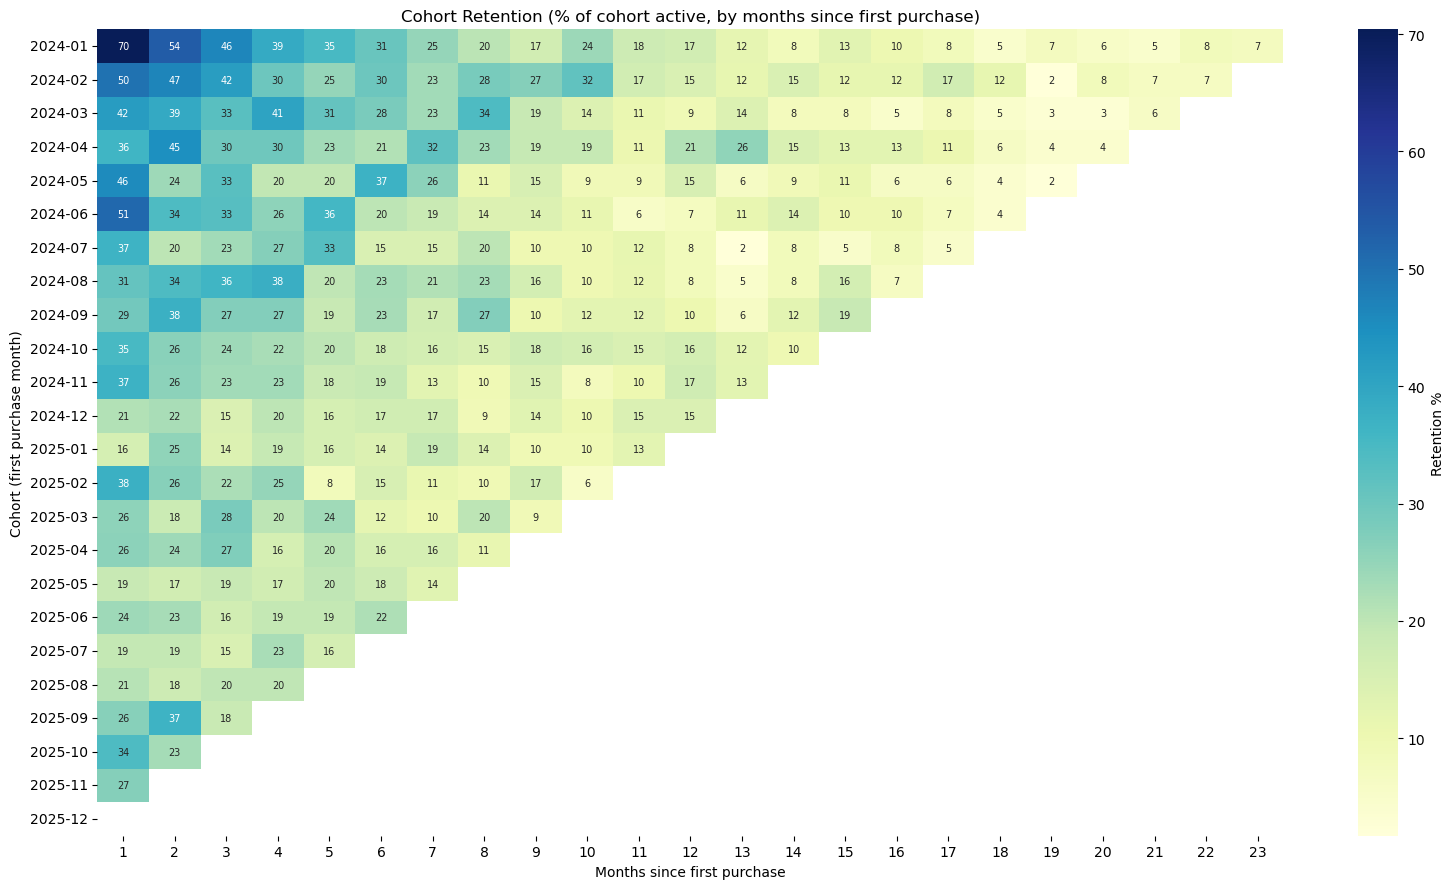

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Column 0 hamesha 100% hota hai, wo color scale bigaadta hai, isliye hata do
plot_data = retention.drop(columns=0)

plt.figure(figsize=(16, 9))
sns.heatmap(
    plot_data,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    annot_kws={'size': 7},
    cbar_kws={'label': 'Retention %'}
)

plt.title('Cohort Retention (% of cohort active, by months since first purchase)')
plt.xlabel('Months since first purchase')
plt.ylabel('Cohort (first purchase month)')
plt.tight_layout()
plt.savefig('../dashboard/cohort_heatmap.png', dpi=150)
plt.show()

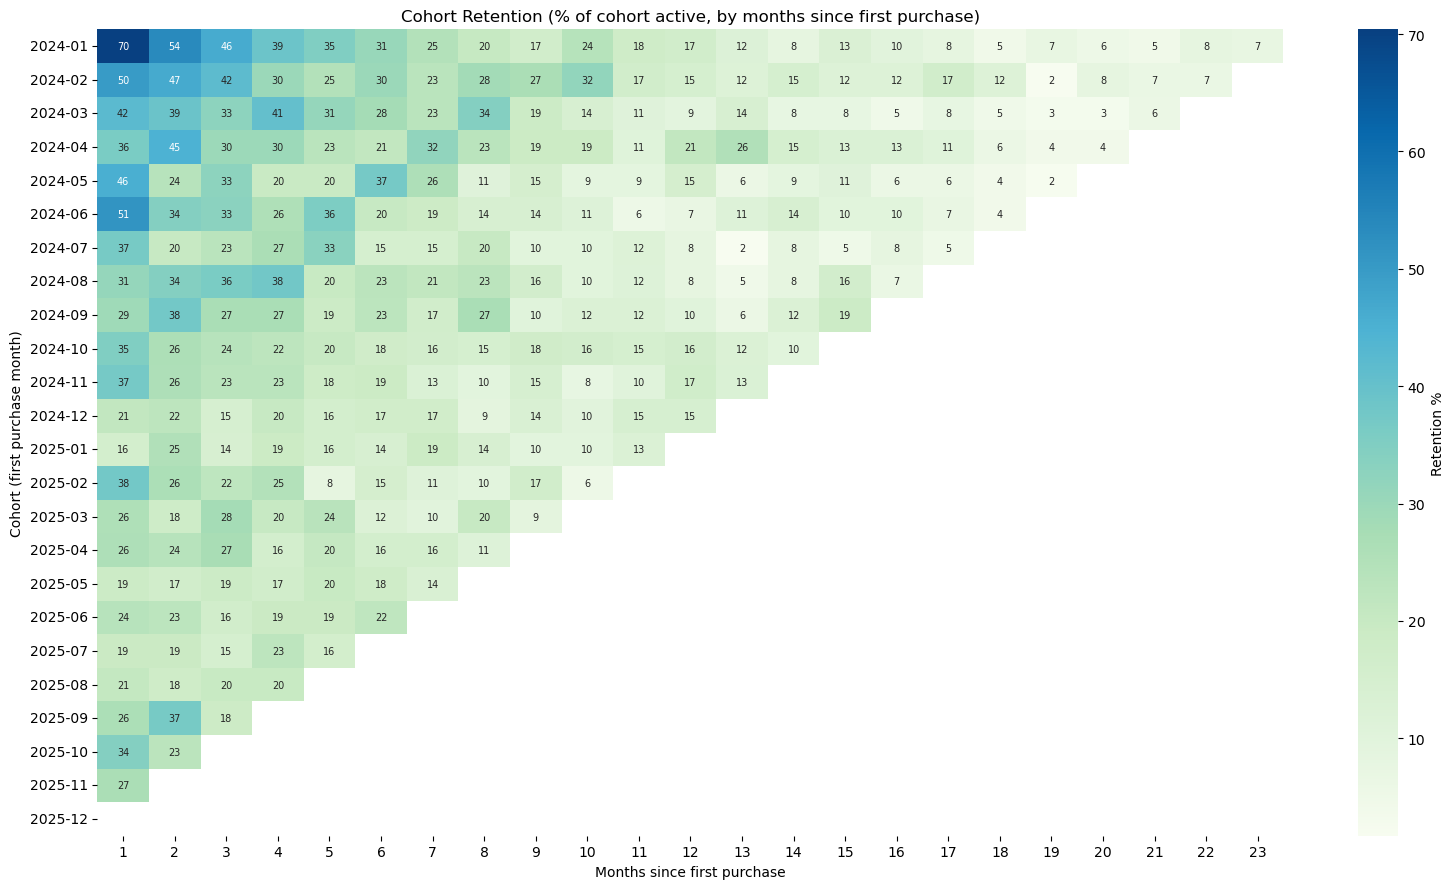

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Column 0 hamesha 100% hota hai, wo color scale bigaadta hai, isliye hata do
plot_data = retention.drop(columns=0)

plt.figure(figsize=(16, 9))
sns.heatmap(
    plot_data,
    annot=True,
    fmt='.0f',
    cmap='GnBu',
    annot_kws={'size': 7},
    cbar_kws={'label': 'Retention %'}
)

plt.title('Cohort Retention (% of cohort active, by months since first purchase)')
plt.xlabel('Months since first purchase')
plt.ylabel('Cohort (first purchase month)')
plt.tight_layout()

plt.show()

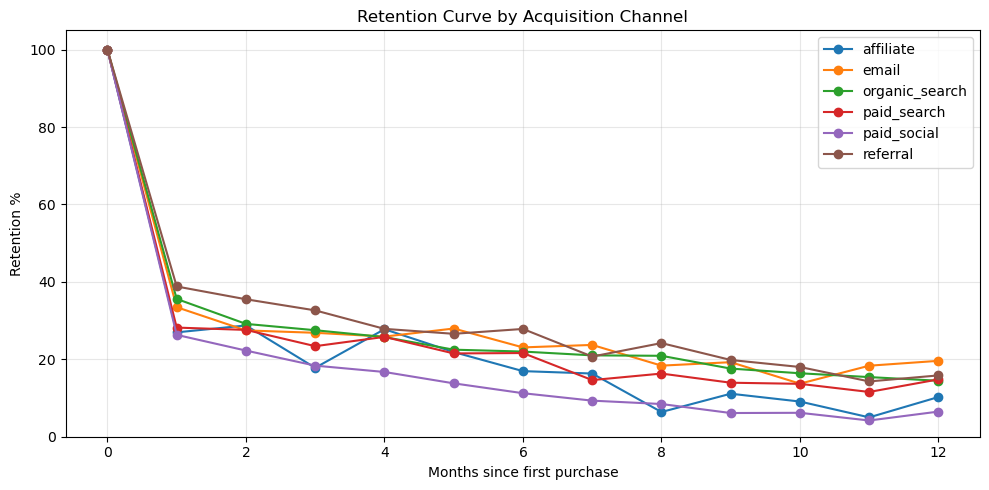

                     customers  total_revenue  avg_revenue  repeat_rate  \
acquisition_channel                                                       
affiliate                   93        63546.0        683.3         64.5   
email                      271       241938.9        892.8         66.1   
organic_search             741       773800.2       1044.3         66.5   
paid_search                327       290349.9        887.9         62.4   
paid_social                367       238406.2        649.6         54.5   
referral                   248       274035.8       1105.0         73.4   

                     ret_m1  ret_m3  ret_m6  
acquisition_channel                          
affiliate              27.0    17.8    16.9  
email                  33.5    26.9    23.1  
organic_search         35.6    27.5    22.0  
paid_search            28.2    23.4    21.6  
paid_social            26.3    18.4    11.2  
referral               38.8    32.6    27.8  


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Data me aakhri mahina kaun sa hai
last_period = sales['order_date'].dt.to_period('M').max()

# 2. Ek channel ki retention curve nikalne wala function
def channel_retention(df, max_month=12):
    # (cohort, index) ke hisaab se unique active customers
    active = (df.groupby(['cohort_month', 'cohort_index'])['customer_id']
                .nunique().reset_index(name='active'))

    # Har cohort ka size (index 0 par kitne customers)
    size = (df[df['cohort_index'] == 0]
            .groupby('cohort_month')['customer_id'].nunique())

    # Har cohort ke liye kitne mahine ka data available hai
    avail = pd.Series((last_period.year - size.index.year) * 12
                      + (last_period.month - size.index.month),
                      index=size.index)

    out = {}
    for k in range(max_month + 1):
        eligible = size[avail >= k].sum()
        got = active.loc[active['cohort_index'] == k, 'active'].sum()
        out[k] = got / eligible * 100 if eligible > 0 else np.nan
    return pd.Series(out)

# 3. Har channel ke liye curve
curves = {ch: channel_retention(g) for ch, g in sales.groupby('acquisition_channel')}
curves_df = pd.DataFrame(curves)

# 4. Plot
plt.figure(figsize=(10, 5))
for ch in curves_df.columns:
    plt.plot(curves_df.index, curves_df[ch], marker='o', label=ch)
plt.title('Retention Curve by Acquisition Channel')
plt.xlabel('Months since first purchase')
plt.ylabel('Retention %')
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('../dashboard/retention_by_channel.png', dpi=150)
plt.show()

# 5. Channel summary table
cust_ch = sales[['customer_id', 'acquisition_channel']].drop_duplicates('customer_id')
cs = (cust_summary.drop(columns='acquisition_channel', errors='ignore')
                  .merge(cust_ch, on='customer_id', how='left'))

summary = cs.groupby('acquisition_channel').agg(
    customers=('customer_id', 'nunique'),
    total_revenue=('total_revenue', 'sum'),
    avg_revenue=('total_revenue', 'mean'),
    repeat_rate=('num_orders', lambda s: (s >= 2).mean() * 100)
)

summary = summary.join(curves_df.T[[1, 3, 6]].rename(
    columns={1: 'ret_m1', 3: 'ret_m3', 6: 'ret_m6'}))

print(summary.round(1))

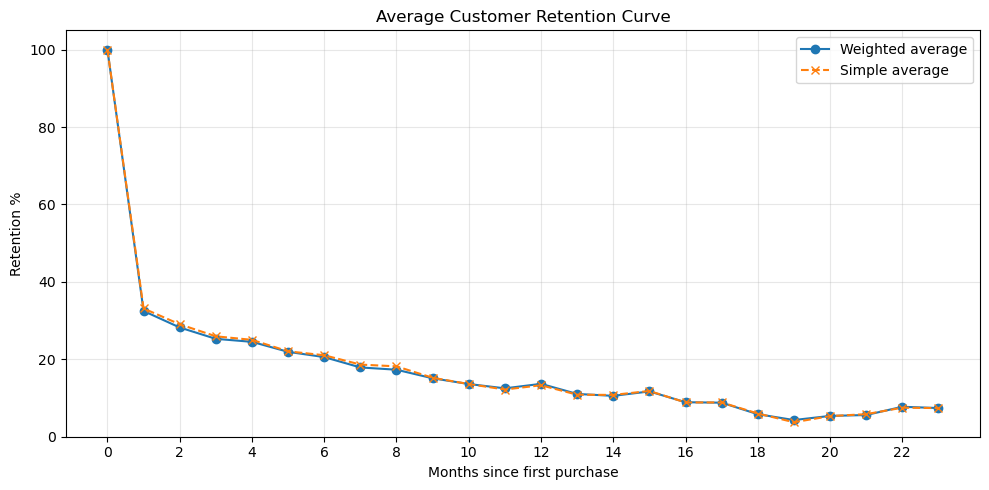

cohort_index
0     100.0
1      32.5
2      28.2
3      25.3
4      24.5
5      21.9
6      20.6
7      17.9
8      17.3
9      15.1
10     13.6
11     12.5
12     13.7
dtype: float64


In [33]:
import matplotlib.pyplot as plt

# 1. Har cohort ka size (column 0)
cohort_size = cohort_count.iloc[:, 0]

# 2. Simple average: har month-column ka cohorts par average %
simple_avg = retention.mean()

# 3. Weighted average: (total active customers) / (total customers jinke liye wo mahina aaya)
mask = cohort_count.notna()
weighted_avg = cohort_count.sum() / mask.mul(cohort_size, axis=0).sum() * 100

# 4. Plot
plt.figure(figsize=(10, 5))
plt.plot(weighted_avg.index, weighted_avg.values, marker='o', label='Weighted average')
plt.plot(simple_avg.index, simple_avg.values, marker='x', linestyle='--', label='Simple average')
plt.title('Average Customer Retention Curve')
plt.xlabel('Months since first purchase')
plt.ylabel('Retention %')
plt.xticks(range(0, 24, 2))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('../dashboard/retention_curve.png', dpi=150)
plt.show()

print(weighted_avg.round(1).head(13))

In [34]:
out = 'C:/Users/ASUS/OneDrive/Desktop/izaan_coding/project/customer-retention-analysis/data/processed/'

# 1. Customer table (segments ke saath)
cs = cust_summary.copy()
cs['cohort_month'] = cs['cohort_month'].astype(str)
cs.to_csv(out + 'pbi_customers.csv', index=False)

# 2. Cohort retention (long format, Power BI me matrix banane ke liye)
ret_long = (retention.reset_index()
                     .melt(id_vars='cohort_month', var_name='months_since_first', value_name='retention_pct')
                     .dropna())
ret_long['cohort_month'] = ret_long['cohort_month'].astype(str)
ret_long.to_csv(out + 'pbi_cohort_retention.csv', index=False)

# 3. Order-level sales
s = sales.copy()
s['cohort_month'] = s['cohort_month'].astype(str)
s.to_csv(out + 'pbi_sales.csv', index=False)